# Pocket milling toolpaths

The example is a CNC pocket of 80 × 50 with two round bosses left standing in it, cleared with a 6 mm end mill. The
tool's center runs along offsets of the pocket's outline, the first at the tool's radius from the walls and each
following one a stepover further in, until nothing is left. What the tool cannot reach remains, which is exactly r² (1 −
π/4) in each sharp corner of the pocket.

![The toolpaths of a pocket with two bosses and the material left in its corners](../_static/gallery/pocket-milling.png){.result}

In [1]:
import math
import matplotlib.pyplot as plt
import planex as px

The pocket is one sketch, with the bosses of radius 6 and 9 as holes:

In [2]:
pocket = px.QuickSketch().Rectangle(80, 50).Circle(22, 25, 6).Circle(55, 22, 9).Face()
print("pocket area", round(pocket.mass, 3), len(pocket.inner), "bosses")

pocket area 3632.434 2 bosses


## Toolpaths

After k passes, the tool's center may go anywhere in the pocket offset inward by d = r + k times the stepover: the
rectangle shrunk by d, minus the bosses grown by d. The tool's radius is `r` = 3, and the stepover is 3 too. The outline
of each region is a toolpath, until the offset leaves nothing.

In [3]:
r = 3.0
passes = []
while True:
    area = pocket.Offset(-(r + len(passes) * 3.0), inplace=False)
    if area.mass < 1e-9:
        break
    passes.append([w for face in area.faces for w in (face.outer, *face.inner)])
length = sum(w.mass for paths in passes for w in paths)
print(len(passes), "passes,", sum(len(p) for p in passes), "loops,", round(length, 1), "mm of toolpath")
print(round(length / 1200, 2), "min at a feed of 1200 mm/min")

4 passes, 10 loops, 1051.8 mm of toolpath
0.88 min at a feed of 1200 mm/min


## What is left

The tool sweeps a band of its radius around every toolpath, which is the path's offset. With the stepover no larger
than the radius, the bands overlap, so only the four corners of the pocket remain. **Check:** what is left is
4 r² (1 − π/4) in total, in four pieces:

In [4]:
swept = px.Unify([w.Offset(r) for paths in passes for w in paths])
rest = pocket - swept
print("left in the pocket", rest.mass, "mm², four corners 4 r² (1 - π/4)", 4 * r**2 * (1 - math.pi / 4), "mm²")
print(len(rest.faces), "pieces")

left in the pocket 7.725666117691862 mm², four corners 4 r² (1 - π/4) 7.725666117691862 mm²
4 pieces


The toolpaths, colored from the first pass to the last, and what is left in red:

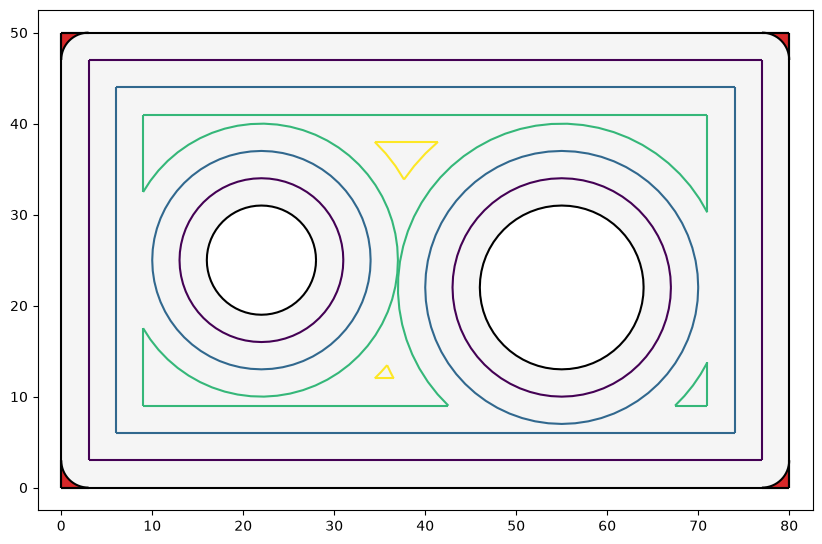

In [5]:
fig, ax = plt.subplots(figsize=(10, 6.5))
pocket.Plot(ax=ax, face_col="whitesmoke", legend=False)
colors = [tuple(c) for c in plt.cm.viridis([k / max(1, len(passes) - 1) for k in range(len(passes))])]
for paths, color in zip(passes, colors):
    for w in paths:
        w.Plot(ax=ax, line_col=color, arc_col=color, spline_col=color, legend=False)
rest.Plot(ax=ax, face_col="tab:red", legend=False)
ax.set_aspect("equal")
plt.show()

In [6]:
import sys
sys.path.insert(0, "..")
from gallery import save_scene, save_figure, save_animation, HIDDEN
save_figure(fig, "pocket-milling", bare=True)